# 03 · Grover search

Run: [setup](../SETUP.md). Qiskit ideal simulation; saved outputs are local. Run your version in qBraid Lab (or implement it in Classiq).

**Input:** a checker that marks one desired bitstring among N possibilities. **Output:** one measured bitstring, with a higher chance of being the target after a suitable number of iterations.

With one solution, Grover needs on the order of √N quantum checker calls, compared with order N classical checks for unstructured search.

A sensor manufacturer wants to find a failing configuration of three firmware flags. Here the failure is `101`. We hardcode that answer to illustrate the algorithm; a useful application needs a reversible checker that recognizes failures without already knowing their locations. This circuit does not execute real firmware.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

print("Qiskit", qiskit.__version__, "| ideal Statevector simulation")
TARGET = "101"
SHOTS = 1024
SEED = 42
N = 8  # Three qubits represent eight possible configurations.

Qiskit 2.3.0 | ideal Statevector simulation


**Three steps**

1. Apply `H` to each qubit: all configurations have equal amplitudes. Squared amplitude magnitude gives measurement probability.
2. Mark the target by reversing its amplitude's sign. This alone changes no probabilities. Reflect amplitudes around their mean; interference increases the target's probability initially. Repeat this pair carefully: too many iterations overshoot.
3. Measure one configuration and check it classically. Each shot repeats the entire preparation and circuit.

Qiskit displays bits as `q2 q1 q0`; the rightmost bit belongs to wire 0.

In [2]:
def mark(circuit, target):
    # Move the target to 111, flip its sign, then undo the moves.
    zero_wires = [q for q, bit in enumerate(reversed(target)) if bit == "0"]
    for q in zero_wires:
        circuit.x(q)
    circuit.h(2)
    circuit.ccx(0, 1, 2)  # H-CCX-H flips only the sign of 111.
    circuit.h(2)
    for q in zero_wires:
        circuit.x(q)


def grover(target, iterations):
    assert len(target) == 3 and set(target) <= {"0", "1"}
    assert isinstance(iterations, int) and iterations >= 0
    circuit = QuantumCircuit(3)
    circuit.h(range(3))
    for _ in range(iterations):
        mark(circuit, target)
        # Reflect around the equal-amplitude state (up to global phase).
        circuit.h(range(3))
        mark(circuit, "000")
        circuit.h(range(3))
    return circuit


# Two small cases: exhaustive classical checking supplies the expected answer.
for target in ["101", "011"]:
    answers = [format(x, "03b") for x in range(N) if format(x, "03b") == target]
    state = Statevector.from_instruction(grover(target, 2))
    most_likely = format(int(np.argmax(state.probabilities())), "03b")
    assert most_likely in answers
print("Both target checks passed.")

Both target checks passed.


Target probability: 2 iterations = 94.5%; 4 iterations = 1.2%


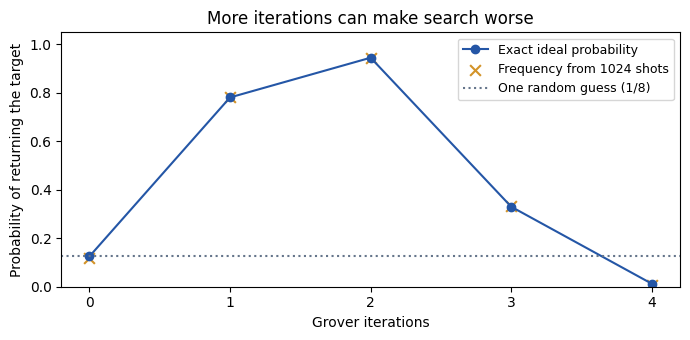

In [3]:
iterations = np.arange(5)
exact, sampled = [], []
for r in iterations:
    state = Statevector.from_instruction(grover(TARGET, int(r)))
    state.seed(SEED + int(r))
    counts = state.sample_counts(SHOTS)
    exact.append(state.probabilities()[int(TARGET, 2)])
    sampled.append(counts.get(TARGET, 0) / SHOTS)
    assert sum(counts.values()) == SHOTS

# Before any search, each of the eight candidates is equally likely.
assert np.isclose(exact[0], 1 / N)
assert exact[2] > exact[4]
print(f"Target probability: 2 iterations = {exact[2]:.1%}; 4 iterations = {exact[4]:.1%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(iterations, exact, "o-", color="#2456a6", label="Exact ideal probability")
ax.scatter(iterations, sampled, marker="x", color="#d39328", s=60,
           label=f"Frequency from {SHOTS} shots")
ax.axhline(1 / N, color="#65758b", linestyle=":", label="One random guess (1/8)")
ax.set(xlabel="Grover iterations", ylabel="Probability of returning the target",
       xticks=iterations, ylim=(0, 1.05), title="More iterations can make search worse")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

**Try:** predict the effect of changing `TARGET` to `011`, then rerun. Should the successful bitstring change? Should the ideal probabilities change? Explain why four iterations underperform two.

Grover's advantage concerns oracle queries in unstructured search, not automatically runtime. Include oracle construction and hardware costs before advising this company; these eight cases are trivial classically. The dotted line is one random guess, not an equal-query benchmark. Sampling variation here is not hardware noise.

Sources: [Grover's original paper](https://arxiv.org/abs/quant-ph/9605043) · [Qiskit Statevector implementation](https://github.com/Qiskit/qiskit/blob/main/qiskit/quantum_info/states/statevector.py).